# Lab: Visualizing Text Data

Select **two distinct text datasets**. Ask **one research question for each dataset** and answer it using the six-step reproducible analysis workflow. Create **two different types of figures for each question**, for a total of two research questions and four figures.

Each pair of figures should provide complementary evidence about the text. You may use Seaborn, Matplotlib, Plotly Express, or WordCloud. Choose datasets whose language is **work appropriate**.


## Learning goals

- Select and document usable text datasets.
- Ask focused questions about vocabulary, text length, or differences between groups.
- Prepare text reproducibly while preserving original wording for context checks.
- Choose and interpret two complementary figures per question.
- Distinguish word occurrences from the number or percentage of documents containing a word.
- Support conclusions with checked evidence and explain the limitations of the data and displays.


## The reproducible analysis workflow

1. **Question:** What do we want to learn?
2. **Data:** Which observations and features can help answer it?
3. **Evidence:** What should we calculate and display to answer the question?
4. **Check:** Does the result make sense in context and agree with the original records?
5. **Conclusion:** What claim is supported?
6. **Limitation:** What should we avoid concluding?

Complete all six steps separately for each dataset. Inspect missing values during Data; use Check to investigate the actual figures and calculations. Use separate code cells for individual operations and add cells as needed.


## Using AI tools responsibly

You may use AI to ask questions, debug code, or receive feedback. You remain responsible for understanding the code, reading the source documentation, and checking every claim against your output. Complete the AI-use reflection at the end.


## Select your two datasets

Each dataset needs:

- A documented source and definitions for the features you use.
- Actual text, such as headlines, posts, descriptions, reviews, or passages—not only ratings or precomputed sentiment scores.
- Enough separate documents or passages to support your question. Define what one row represents.
- Relevant group labels if you plan to compare categories, authors, sources, or ratings. Document any groups you create.

Use two distinct datasets, not two filters of the same collection. A comparison of two categories from one collection counts as **one dataset and one investigation**. Choose your own questions rather than repeating the SMS lecture. Other documented sources are welcome.

Choose a manageable subset before analysis and document any sampling and its random seed. Save fixed copies in this notebook's `data` folder and use relative paths. Preserve the original text alongside prepared features. If you assemble passages from books, document their boundaries and retain book and author identifiers; passages from one book are not independent samples of all literature.

### Work-appropriate language

Be mindful that your datasets should be **work appropriate** for a classroom presentation. Read sample records and review the words, excerpts, and hover text that your figures will display. Public availability does not guarantee appropriate content. Choose another source or document any content-based exclusions when needed; explain how screening may affect your results. Review the final outputs before submitting. The suggestions below have not been screened for you.


### Candidate datasets

| Candidate and source | Useful text and grouping information | Possible question and figure pair |
| --- | --- | --- |
| [UCI News Aggregator](https://archive.ics.uci.edu/dataset/359/news+aggregator) | News titles, category, publisher, and story identifiers. Use `newsCorpora.csv` and its README; analyze titles rather than assuming the file contains full articles. Start with two categories and a manageable sample. | How does vocabulary differ between business and science/technology headlines? Use a word-frequency bar chart and a word-frequency scatter plot. Repeated coverage of the same story may affect counts. |
| [20 Newsgroups through scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.fetch_20newsgroups.html) | Posts and topic labels. Consider `rec.sport.baseball` and `sci.space`. The loader supports selecting categories and removing headers, footers, and quoted replies. Save the selected text and labels locally. | How do vocabulary and post length differ between baseball and space discussions? Use grouped word-frequency bars and a text-length box plot. Screen the posts; topic selection does not guarantee clean language. |
| [Project Gutenberg](https://www.gutenberg.org/) | Downloadable books with author and title information. Assemble a collection of clearly defined passages or chapters from selected books and preserve their source identifiers. Remove book headers and license boilerplate from the analysis copy. | Which words characterize selected adventure and nature-writing books? Use word clouds and a grouped word-frequency chart. Multiple books per group support a broader comparison than one book per group. |

Adapt the question to the available fields. A second pair of categories from the same collection does not satisfy the second-dataset requirement. The questions and chart pairs are starting points, not required choices.


## Choose two complementary figures per question

Choose **different chart types**, not two versions differing only in color, title, selected words, or counts versus percentages. You may reuse a chart type for the second dataset. A group of word clouds counts as one figure type; it cannot supply both figures by itself. At least one figure per question must support a numerical comparison, such as a bar chart, scatter plot, box plot, or heatmap.

| Figure | Tools | What it can help you see |
| --- | --- | --- |
| Word cloud | `WordCloud` and Matplotlib | An initial impression of prominent vocabulary. Each cloud scales its own words; font sizes are not precise comparisons across clouds. |
| Word-frequency bar chart | `sns.barplot()` or `px.bar()` | Exact occurrences or the percentage of documents containing selected words. State the denominator and use the same word selection across groups. |
| Word-frequency scatter plot | `px.scatter()` | Each point is a word, with its document percentage in group A on x and group B on y. Use equal scales and an equal-percentage reference line. |
| Text-length box plot or histogram | `sns.boxplot()`, `sns.histplot()`, `px.box()`, or `px.histogram()` | How document lengths vary within or across groups. Define length in words or characters. Length alone does not measure sentiment or quality. |
| Word-by-group heatmap—an additional option | `sns.heatmap()` or `px.imshow()` | How the percentage of documents containing a word varies across several groups. Use one common color scale and state its units. |

Keep different measures in separate figures. Explain how each figure helps answer the same research question. A plot of group sizes is useful context, but it cannot replace a required text-analysis figure unless it directly answers your question about the text.


### Preparation and interpretation guidance

- Preserve an original-text column and a document identifier. Decide how to handle blank text, duplicates, URLs, punctuation, case, and boilerplate.
- Start with scikit-learn's `ENGLISH_STOP_WORDS` for English text, then use an editable `additional_stopwords` list as in the lecture. Justify additions and apply the same choices to compared groups. Other languages need appropriate preparation.
- Report how many documents are in each group. Unequal numbers of documents and different document lengths affect raw word counts.
- **Word occurrences** count every repetition. **Percent of documents containing a word** counts each document once, divided by all documents in that group, including documents without the word. This is not the percentage of a word's matches that belong to a group.
- Define and document any display threshold or top-word selection. A word absent from the displayed chart is not necessarily absent from the data.
- Use descriptive titles, readable labels, common scales for common measures, and useful hover information where applicable. Keep counts and percentages on separate figures.
- Reuse or adapt the lecture's preparation and sample-message function, explaining your changes. No classifier, sentiment model, or train/test split is required.


### Starting pattern for an additional chart type

This is an **adaptation example**, not code to run unchanged. It assumes `tokens_df` has one row per retained word occurrence, with `document_id`, `group`, and `word`, and `documents_df` has one row per document. Replace these names with yours.

```python
# Count each document once per word, even if the word repeats.
word_counts = tokens_df.groupby(['group', 'word'])['document_id'].nunique().reset_index(name='documents_with_word')
group_sizes = documents_df.groupby('group')['document_id'].nunique()
word_counts['percent_documents'] = 100 * word_counts['documents_with_word'] / word_counts['group'].map(group_sizes)

# Show the ten words occurring in the most documents overall.
selected_words = tokens_df.groupby('word')['document_id'].nunique().nlargest(10).index
grid = word_counts.pivot(index='word', columns='group', values='percent_documents')
grid = grid.reindex(index=selected_words, columns=group_sizes.index).fillna(0)
sns.heatmap(grid, annot=True, fmt='.1f', cmap='Blues',
            cbar_kws={'label': 'Percent of documents in each group containing the word'})
plt.xlabel('Group')
plt.ylabel('Word')
plt.title('Selected vocabulary across groups')
plt.show()
```

Use unique document IDs across the collection. Here zero means no retained occurrence was observed in a group with documents; it does not replace missing source text. Choose a manageable number of words and groups so labels remain readable.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from sklearn.feature_extraction.text import (
    CountVectorizer,
    ENGLISH_STOP_WORDS
)
from sklearn.datasets import fetch_20newsgroups


## Investigation 1: Your dataset and research question


### Step 1: Question

Ask one focused question about the text. Identify the documents, groups if relevant, and the vocabulary or text-derived feature you will examine. Record a prediction before producing figures.


**What is your research question, and what do you predict? Why is text analysis useful for answering it?**

Your answer:How does vocabulary differ between business and science/technology headlines in the UCI News Aggregator dataset? I will compare the percentage of headlines in each group containing selected words, using a bar chart and a word-frequency scatterplot. Text analysis is useful because it summarizes vocabulary across many headlines rather than relying on a few examples.

I expect business headlines to emphasize companies and markets, while science/technology headlines emphasize devices and research. I also expect some shared vocabulary


### Step 2: Data

Document the source and explain what one row represents. Load a fixed copy, inspect the first and last rows and shape, use `.info()` to inspect the data storage types and non-missing values, and count missing values. Identify blank text separately from missing values.


**Give the dataset title, publisher, direct source URL, feature-definition reference, and access date. Identify your saved files.**

Your answer:


**What does one row represent? What texts and groups are covered, and how were they collected? How did you check that the language and displayed examples are work appropriate?**

Your answer:


In [2]:
news_columns = [
    "document_id", "original_text", "url", "publisher",
    "category", "story_id", "hostname", "timestamp"
]

news_df = pd.read_csv(
    "data/newsCorpora.csv",
    sep="\t",
    header=None,
    names=news_columns,
    dtype={
        "document_id": str,
        "category": str,
        "story_id": str
    }
)


In [3]:
news_df.head()


,document_id,original_text,url,publisher,category,story_id,hostname,timestamp
0,1,"Fed official says weak data caused by weather,...",http://www.latimes.com/business/money/la-fi-mo...,Los Angeles Times,b,ddUyU0VZz0BRneMioxUPQVP6sIxvM,www.latimes.com,1394470370698
1,2,Fed's Charles Plosser sees high bar for change...,http://www.livemint.com/Politics/H2EvwJSK2VE6O...,Livemint,b,ddUyU0VZz0BRneMioxUPQVP6sIxvM,www.livemint.com,1394470371207
2,3,US open: Stocks fall after Fed official hints ...,http://www.ifamagazine.com/news/us-open-stocks...,IFA Magazine,b,ddUyU0VZz0BRneMioxUPQVP6sIxvM,www.ifamagazine.com,1394470371550
3,4,"Fed risks falling 'behind the curve', Charles ...",http://www.ifamagazine.com/news/fed-risks-fall...,IFA Magazine,b,ddUyU0VZz0BRneMioxUPQVP6sIxvM,www.ifamagazine.com,1394470371793
4,5,Fed's Plosser: Nasty Weather Has Curbed Job Gr...,http://www.moneynews.com/Economy/federal-reser...,Moneynews,b,ddUyU0VZz0BRneMioxUPQVP6sIxvM,www.moneynews.com,1394470372027


In [4]:
news_df.tail()

,document_id,original_text,url,publisher,category,story_id,hostname,timestamp
422414,422933,Surgeons to remove 4-year-old's rib to rebuild...,http://www.cbs3springfield.com/story/26378648/...,WSHM-TV,m,dpcLMoJD69UYMXMxaoEFnWql9YjQM,www.cbs3springfield.com,1409229190251
422415,422934,Boy to have surgery on esophagus after battery...,http://www.wlwt.com/news/boy-to-have-surgery-o...,WLWT Cincinnati,m,dpcLMoJD69UYMXMxaoEFnWql9YjQM,www.wlwt.com,1409229190508
422416,422935,Child who swallowed battery to have reconstruc...,http://www.newsnet5.com/news/local-news/child-...,NewsNet5.com,m,dpcLMoJD69UYMXMxaoEFnWql9YjQM,www.newsnet5.com,1409229190771
422417,422936,Phoenix boy undergoes surgery to repair throat...,http://www.wfsb.com/story/26368078/phoenix-boy...,WFSB,m,dpcLMoJD69UYMXMxaoEFnWql9YjQM,www.wfsb.com,1409229191071
422418,422937,Phoenix boy undergoes surgery to repair throat...,http://www.cbs3springfield.com/story/26368078/...,WSHM-TV,m,dpcLMoJD69UYMXMxaoEFnWql9YjQM,www.cbs3springfield.com,1409229191565


In [5]:
news_df.shape

(422419, 8)

In [6]:
news_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 422419 entries, 0 to 422418
Data columns (total 8 columns):
 #   Column         Non-Null Count   Dtype
---  ------         --------------   -----
 0   document_id    422419 non-null  str  
 1   original_text  422419 non-null  str  
 2   url            422419 non-null  str  
 3   publisher      422417 non-null  str  
 4   category       422419 non-null  str  
 5   story_id       422419 non-null  str  
 6   hostname       422419 non-null  str  
 7   timestamp      422419 non-null  int64
dtypes: int64(1), str(7)
memory usage: 114.9 MB


In [7]:
news_df.isna().sum()

document_id      0
original_text    0
url              0
publisher        2
category         0
story_id         0
hostname         0
timestamp        0
dtype: int64

In [8]:
print(
    "Blank headlines:",
    news_df["original_text"].fillna("").str.strip().eq("").sum()
)

display(news_df["category"].value_counts(dropna=False))

Blank headlines: 0


category
e    152469
b    115967
t    108344
m     45639
Name: count, dtype: int64

In [9]:
news_candidates_df = news_df.loc[
    news_df["category"].isin(["b", "t"])
].copy()

news_candidates_df["group"] = news_candidates_df["category"].map({
    "b": "Business",
    "t": "Science/Technology"
})

news_candidates_df["headline_key"] = (
    news_candidates_df["original_text"]
    .str.strip()
    .str.lower()
)

print("Selected-category records:", len(news_candidates_df))
print(
    "Duplicate document IDs:",
    news_candidates_df["document_id"].duplicated().sum()
)
print(
    "Repeated headlines within categories:",
    news_candidates_df.duplicated(["group", "headline_key"]).sum()
)


Selected-category records: 224311
Duplicate document IDs: 0
Repeated headlines within categories: 8516


In [10]:
news_unique_df = news_candidates_df.drop_duplicates(
    ["group", "headline_key"]
).copy()

news_sample_df = pd.concat([
    group_df.sample(n=500, random_state=42)
    for _, group_df in news_unique_df.groupby("group", sort=True)
]).sort_values(["group", "document_id"]).reset_index(drop=True)

news_sample_df.to_csv("data/news_sample.csv", index=False)

display(news_sample_df["group"].value_counts())

display(
    news_sample_df.groupby("group", group_keys=False)
    .sample(n=10, random_state=42)[
        ["document_id", "group", "original_text"]
    ]
)

group
Business              500
Science/Technology    500
Name: count, dtype: int64

,document_id,group,original_text
361,364448,Business,ADM to buy Swiss flavouring maker
73,163255,Business,Microsoft's quarterly results beat investor ex...
374,38006,Business,Gold Rebounds From One-Month Low as Ukraine Sp...
155,213247,Business,"Why Shares of World Wrestling Entertainment, I..."
104,188248,Business,China's Alibaba could raise billions in IPO
394,394316,Business,Stocks drift as traders await key economic news
377,383264,Business,"Benchmark Treasurys rise after data, Fed"
124,197089,Business,What will Yahoo do with its Alibaba windfall?
68,158781,Business,"Asian shares struggle, dollar slips as Ukraine..."
450,61035,Business,Ga. teen accused of spending cash after bank e...


**Complete the table for every feature used in the question, preparation, or figures. Add rows as needed.**
| Feature | Meaning and units or codes | Feature type | Data storage type | Missing values |
|---|---|---|---|---|
| document_id | Original news-record identifier | Categorical identifier | str | 0 |
| original_text | Original headline title | Text | str | 0 |
| category | b = business; t = science/technology | Categorical | str | 0 |
| story_id | Identifier linking coverage of the same story | Categorical identifier | str | 0 |
| group | Readable label for the selected category | Categorical | Check after creation | Check after creation |
| headline_key | Lowercase, trimmed headline used to identify duplicates | Text | Check after creation | Check after creation |
| prepared_text | Headline with URLs removed, used for tokenization | Text | Check after creation | Check after creation |
Your answer:


**Which records and features will you use? Explain your groups, sampling, missing or blank text, duplicates, content screening, and text-preparation decisions, including stopwords.**

Your answer:I selected business and science/technology headlines, removed repeated headlines within each category using a lowercase, whitespace-trimmed key, and sampled 500 headlines per group with random_state=42. Original text and identifiers are preserved. The source has no missing or blank headlines; missing publisher names do not affect vocabulary analysis.

I will lowercase text, remove URLs, and retain alphabetic words of at least two letters. I will use scikit-learn’s English stopwords with no additional stopwords initially, applying identical preparation to both groups. Each word will count at most once per headline. Content screening is still in progress: sample headlines and all words or excerpts displayed in the final figures must be reviewed for classroom suitability.


In [11]:
additional_stopwords = []

stopwords = sorted(
    set(ENGLISH_STOP_WORDS) | set(additional_stopwords)
)

news_sample_df["prepared_text"] = (
    news_sample_df["original_text"]
    .str.replace(r"https?://\S+|www\.\S+", " ", regex=True)
)

vectorizer = CountVectorizer(
    lowercase=True,
    stop_words=stopwords,
    token_pattern=r"(?u)\b[a-zA-Z]{2,}\b",
    binary=True
)

word_matrix = vectorizer.fit_transform(
    news_sample_df["prepared_text"]
)

words = vectorizer.get_feature_names_out()

news_word_counts_df = pd.DataFrame({
    "word": words,
    "documents_with_word": word_matrix.sum(axis=0).A1
})

display(
    news_word_counts_df.nlargest(30, "documents_with_word")
)

print("Original records:", len(news_df))
print("Selected-category records:", len(news_candidates_df))
print("After headline deduplication:", len(news_unique_df))
print("Sampled headlines:", len(news_sample_df))
display(news_sample_df["group"].value_counts())


,word,documents_with_word
1676,new,55
1074,google,53
110,apple,49
2188,samsung,39
1568,microsoft,35
427,china,28
883,facebook,26
2454,stocks,26
1016,galaxy,25
610,deal,24


Original records: 422419
Selected-category records: 224311
After headline deduplication: 215795
Sampled headlines: 1000


group
Business              500
Science/Technology    500
Name: count, dtype: int64

**How many records were removed from the dataset? Explain why, and state what one row represents in each analysis table.**

Your answer:The original file contained 422,419 records. Selecting business and science/technology retained 224,311 records, excluding 198,108 from other categories. Removing repeated lowercase, whitespace-trimmed headlines within each category excluded another 8,516 records, leaving 215,795. I then sampled 500 headlines per group using random_state=42, producing 1,000 analyzed headlines; the other 214,795 eligible headlines were not sampled.

Each row in news_sample_df represents one sampled headline with its original text and identifiers preserved. Each row in news_word_counts_df represents one retained word and the number of sampled headlines containing it. Repeated occurrences within a headline count only once.


In [12]:
group_word_tables = []

for group in ["Business", "Science/Technology"]:
    mask = news_sample_df["group"].eq(group).to_numpy()
    counts = word_matrix[mask].sum(axis=0).A1
    group_size = int(mask.sum())

    group_word_tables.append(pd.DataFrame({
        "word": words,
        "group": group,
        "documents_with_word": counts,
        "group_size": group_size,
        "percent_documents": counts / group_size * 100
    }))

news_group_words_df = pd.concat(
    group_word_tables, ignore_index=True
)

selected_words = (
    news_word_counts_df
    .sort_values(
        ["documents_with_word", "word"],
        ascending=[False, True]
    )
    .head(15)["word"]
    .tolist()
)

news_plot_df = news_group_words_df.loc[
    news_group_words_df["word"].isin(selected_words)
].copy()

display(news_plot_df)

,word,group,documents_with_word,group_size,percent_documents
110,apple,Business,1,500,0.2
330,buy,Business,13,500,2.6
427,china,Business,24,500,4.8
607,day,Business,10,500,2.0
610,deal,Business,19,500,3.8
883,facebook,Business,3,500,0.6
1016,galaxy,Business,0,500,0.0
1064,gm,Business,6,500,1.2
1074,google,Business,6,500,1.2
1568,microsoft,Business,2,500,0.4


### Step 3: Evidence

Create two different figure types that answer this same question. At least one must support a numerical comparison. Use consistent preparation and explain any difference in the records or words displayed.


**Which two chart types will you use, and what should each make easier to answer? Specify what positions, colors, and sizes represent and define any percentage denominator.**

Your answer:I will use a grouped horizontal bar chart and a word-frequency scatterplot. The bar chart compares the percentage of headlines containing each selected word, with color identifying the category. The scatterplot places Business percentages on the horizontal axis and Science/Technology percentages on the vertical axis. Each equal-sized point represents one word; an equal-percentage reference line highlights differences between groups.

Both figures use the 15 words appearing in the most sampled headlines overall. Each percentage uses all 500 headlines in its category as the denominator, counting each headline once per word regardless of repetitions.


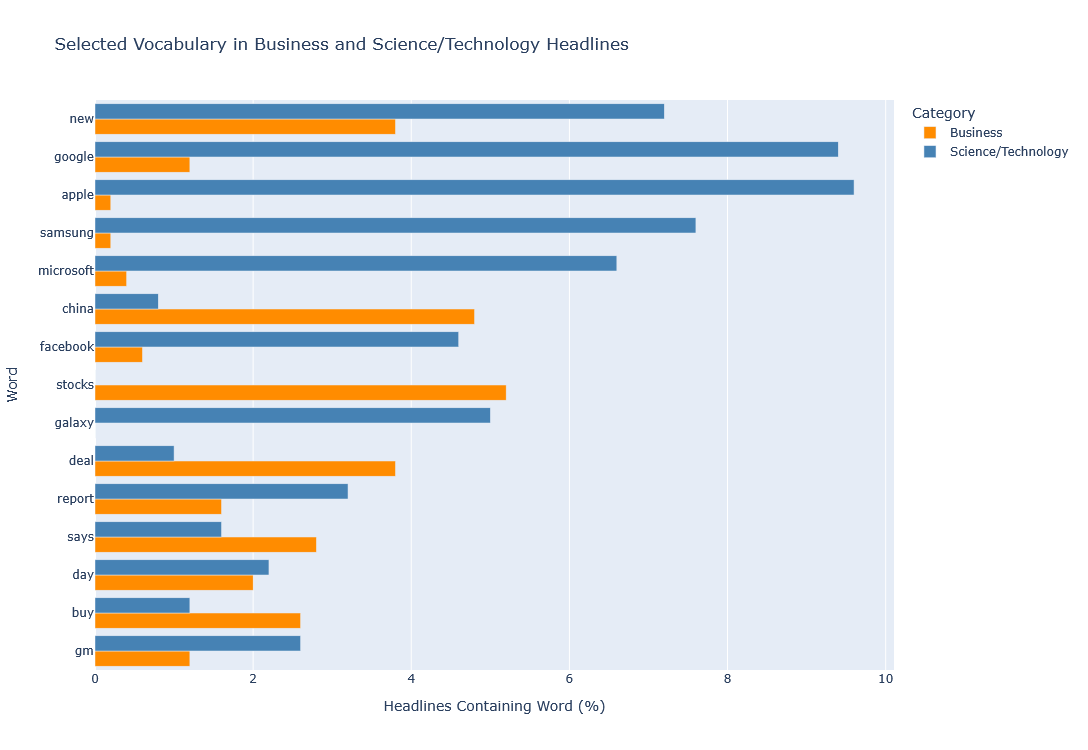

In [13]:
news_colors = {
    "Business": "darkorange",
    "Science/Technology": "steelblue"
}

fig = px.bar(
    news_plot_df,
    x="percent_documents",
    y="word",
    color="group",
    orientation="h",
    barmode="group",
    category_orders={"word": selected_words},
    color_discrete_map=news_colors,
    hover_data=["documents_with_word", "group_size"],
    labels={
        "percent_documents": "Headlines Containing Word (%)",
        "word": "Word",
        "group": "Category"
    },
    title="Selected Vocabulary in Business and Science/Technology Headlines"
)

fig.update_layout(height=750)
fig.show()


**What does Figure 1 show? Describe a pattern and record at least one supporting value, identifying its word or text feature, group, and units.**

Your answer:Figure 1 shows differences in the percentage of sampled headlines containing selected words. “Apple” appears in 9.6% of Science/Technology headlines (48 of 500), compared with 0.2% of Business headlines (1 of 500). “Google” also appears more often in Science/Technology: 9.4% versus 1.2%. In contrast, “stocks” appears in 5.2% of Business headlines and none of the sampled Science/Technology headlines.

These results suggest more technology-brand vocabulary in Science/Technology and more market-related vocabulary in Business. The percentages describe the sampled headlines, not all news, and count each headline only once per word.


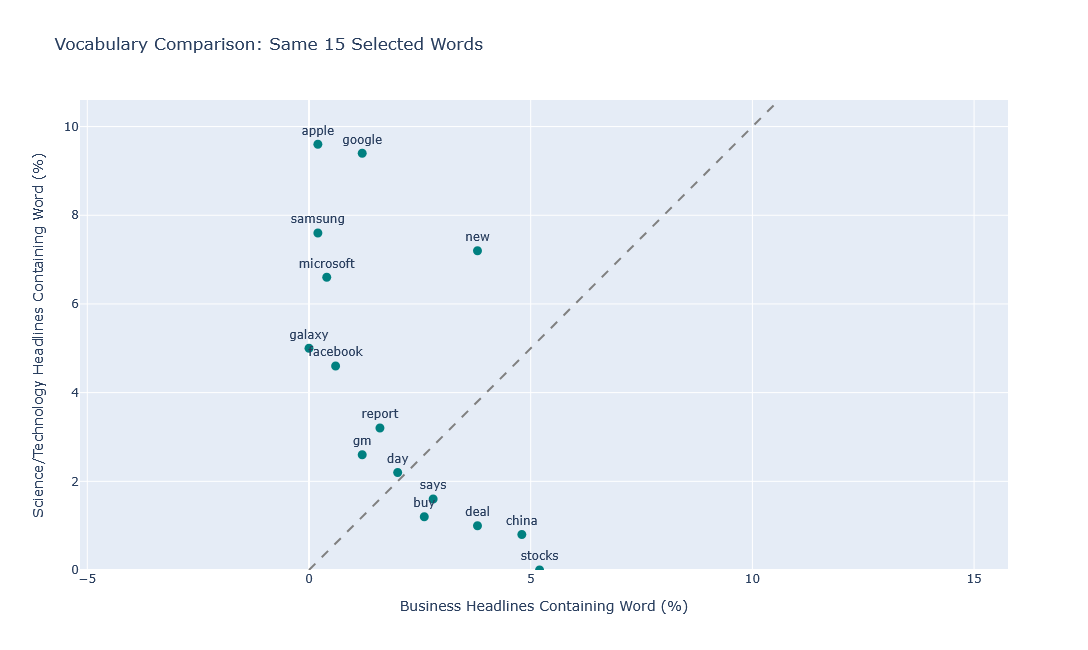

In [14]:
news_scatter_df = news_plot_df.pivot(
    index="word",
    columns="group",
    values="percent_documents"
).reset_index()

axis_limit = (
    news_scatter_df[["Business", "Science/Technology"]]
    .to_numpy().max() + 1
)

fig = px.scatter(
    news_scatter_df,
    x="Business",
    y="Science/Technology",
    text="word",
    hover_name="word",
    labels={
        "Business": "Business Headlines Containing Word (%)",
        "Science/Technology":
            "Science/Technology Headlines Containing Word (%)"
    },
    title="Vocabulary Comparison: Same 15 Selected Words"
)

fig.update_traces(
    textposition="top center",
    marker=dict(size=9, color="teal")
)
fig.add_shape(
    type="line",
    x0=0, y0=0,
    x1=axis_limit, y1=axis_limit,
    line=dict(color="gray", dash="dash")
)
fig.update_xaxes(range=[0, axis_limit])
fig.update_yaxes(
    range=[0, axis_limit],
    scaleanchor="x",
    scaleratio=1
)
fig.update_layout(height=650, width=750)
fig.show()


**What does Figure 2 add? Record at least one supporting value and compare its message with Figure 1.**

Your answer:Figure 2 makes differences between categories easy to see relative to the equal-percentage line. Words above the line occur in a greater percentage of Science/Technology headlines; words below it occur more often in Business headlines.

For example, “apple” is at 0.2% Business and 9.6% Science/Technology, a difference of 9.4 percentage points. “Stocks” is at 5.2% Business and 0% Science/Technology. “Day,” at 2.0% and 2.2%, is close to the line and has similar prevalence in both groups.

Figure 1 makes individual percentages easy to compare, while Figure 2 emphasizes the direction and size of differences across the same 15 selected words.


### Step 4: Check

Verify at least two plotted values against records or calculated summaries. Read a few original texts containing a selected word or illustrating a pattern, using the lecture's sample function or your own code. For grouped comparisons, check examples from each relevant group when matches exist. Explain whether context supports your interpretation. Do not repeat the initial missing-value count.


In [15]:
analyzer = vectorizer.build_analyzer()

for word in ["apple", "stocks"]:
    print("\nWORD:", word)

    for group in ["Business", "Science/Technology"]:
        group_df = news_sample_df.loc[
            news_sample_df["group"] == group
        ]

        matches = group_df["original_text"].apply(
            lambda text: word in analyzer(text)
        )

        print(
            group,
            "Matching headlines:", int(matches.sum()),
            "Total headlines:", len(group_df),
            "Percentage:", round(matches.mean() * 100, 1)
        )

        with pd.option_context("display.max_colwidth", None):
            display(
                group_df.loc[
                    matches, ["document_id", "original_text"]
                ].head(3)
            )



WORD: apple
Business Matching headlines: 1 Total headlines: 500 Percentage: 0.2


,document_id,original_text
120,196776,Apple reportedly planning to buy Beats for $3.2B


Science/Technology Matching headlines: 48 Total headlines: 500 Percentage: 9.6


,document_id,original_text
527,117611,Compliance Monitor Says Relationship With Apple Has 'Significantly Improved'
528,117678,New system will bring Apple's CarPlay to any car this fall
571,150264,Microsoft's Cortana to take on Apple's Siri and Google Now



WORD: stocks
Business Matching headlines: 26 Total headlines: 500 Percentage: 5.2


,document_id,original_text
1,101596,"Stocks fall on jitters over earnings, tech rout - Business, Government Legal News ..."
13,112510,GLOBAL MARKETS-Stocks climb on upbeat US data; euro falls
14,112516,Europe close: Stocks little changed amid Ukraine turmoil


Science/Technology Matching headlines: 0 Total headlines: 500 Percentage: 0.0


,document_id,original_text


**Which two values did you check, and did they agree? What did the original text reveal that the figures could not? Describe any correction you made.**

Your answer:I checked “apple” and “stocks” using the same tokenization rules as the figures. “Apple” appeared in 1 of 500 Business headlines (0.2%) and 48 of 500 Science/Technology headlines (9.6%). “Stocks” appeared in 26 of 500 Business headlines (5.2%) and no sampled Science/Technology headlines (0%). These values agreed with both figures.

The displayed original headlines confirmed that “Apple” referred to the technology company rather than the fruit, while “stocks” referred to financial markets. The Business headline about Apple buying Beats also showed how technology companies can appear in business coverage. The charts alone cannot reveal this context. No calculation corrections were needed.


### Step 5: Conclusion

Restate your research question, then answer it using evidence from **both** figures. Include numerical values with clear units or denominators and explain whether the evidence supports your prediction.


**Restate your question and write your conclusion.**

Your answer:My question was how vocabulary differs between Business and Science/Technology headlines. Among 500 sampled headlines per group, “apple” appeared in 9.6% of Science/Technology headlines versus 0.2% of Business headlines. “Stocks” appeared in 5.2% of Business headlines and none of the sampled Science/Technology headlines. The bar chart shows these percentages directly, while the scatterplot highlights differences relative to equal prevalence. Original examples supported interpreting these as technology-company and financial-market vocabulary.


### Step 6: Limitation

Identify **two limitations of your analysis**. Then explain which aspects of your question are easier or harder to answer from each figure.


**What are two limitations, and how do the strengths and weaknesses of your figures affect the answer?**

Your answer:First, the sample comes from a historical news collection and does not represent all news. Deduplicating identical headlines does not eliminate different headlines covering the same story, so repeated coverage may influence the results.

Second, tokenization, stopwords, and selecting only 15 words affect what is displayed. Word presence alone does not establish meaning or sentiment. The bar chart makes percentages easier to read, and the scatterplot emphasizes differences between groups, but neither shows sentence context or omitted vocabulary.


## Investigation 2: Your dataset and research question


### Step 1: Question

Ask one focused question about the text. Identify the documents, groups if relevant, and the vocabulary or text-derived feature you will examine. Record a prediction before producing figures.


**What is your research question, and what do you predict? Why is text analysis useful for answering it?**

Your answer:How do vocabulary and post length differ between rec.sport.baseball and sci.space posts in the 20 Newsgroups dataset? I will compare selected words using a document-percentage bar chart and compare post lengths using a box plot. Text analysis can summarize patterns across many posts while preserving original examples for context.


### Step 2: Data

Document the source and explain what one row represents. Load a fixed copy, inspect the first and last rows and shape, use `.info()` to inspect the data storage types and non-missing values, and count missing values. Identify blank text separately from missing values.


**Give the dataset title, publisher, direct source URL, feature-definition reference, and access date. Identify your saved files.**

Your answer:Dataset: 20 Newsgroups, restricted to rec.sport.baseball and sci.space.

Distributor: scikit-learn’s dataset collection.
Original collection and background: https://qwone.com/~jason/20Newsgroups/
Loader and feature definitions: https://scikit-learn.org/stable/modules/generated/sklearn.datasets.fetch_20newsgroups.html

Access date: November 22, 2026.
Saved file: data/baseball_space_posts.csv.

The local file preserves original post text, a document identifier, a source filename, the newsgroup label, and a separate body-text version with headers, footers, and quoted replies removed by the loader.


**What does one row represent? What texts and groups are covered, and how were they collected? How did you check that the language and displayed examples are work appropriate?**

Your answer:One row represents one archived Usenet discussion post assigned to either rec.sport.baseball or sci.space. These are topic-group posts from the historical 20 Newsgroups collection, rather than a random sample of current baseball or space discussions. I selected both groups from the combined collection using subset="all"; no predictive model or train/test comparison is planned.

Content screening is not yet complete. Before displaying final figures and examples, I will read sample post bodies from both groups and review the selected vocabulary and excerpts for classroom suitability. Any content-based exclusions will be documented. Removing headers, footers, and quotes is imperfect and does not guarantee appropriate content.


In [16]:
categories = ["rec.sport.baseball", "sci.space"]

raw_posts = fetch_20newsgroups(
    subset="all",
    categories=categories,
    shuffle=False,
    remove=()
)

clean_posts = fetch_20newsgroups(
    subset="all",
    categories=categories,
    shuffle=False,
    remove=("headers", "footers", "quotes")
)

assert (raw_posts.filenames == clean_posts.filenames).all()

posts_df = pd.DataFrame({
    "document_id": [
        f"post_{i}" for i in range(len(raw_posts.data))
    ],
    "source_file": [
        str(path).replace("\\", "/").split("/")[-1]
        for path in raw_posts.filenames
    ],
    "group": [
        raw_posts.target_names[label]
        for label in raw_posts.target
    ],
    "original_text": raw_posts.data,
    "body_text": clean_posts.data
})

posts_df.to_csv("data/baseball_space_posts.csv", index=False)


In [17]:
posts_df = pd.read_csv(
    "data/baseball_space_posts.csv",
    dtype={"document_id": str, "source_file": str},
    keep_default_na=False
)

In [18]:
posts_df.head()


,document_id,source_file,group,original_text,body_text
0,post_0,102736,rec.sport.baseball,From: cubbie@garnet.berkeley.edu ( ...,\nmorgan and guzman will have era's 1 run high...
1,post_1,104930,rec.sport.baseball,From: roger@crux.Princeton.EDU (Roger Lustig)\...,"\n\n\n\n\nUm, the header said *career.* Hodap..."
2,post_2,60895,sci.space,From: aws@iti.org (Allen W. Sherzer)\nSubject:...,\n\nI think I can. Largely as a result of effo...
3,post_3,60824,sci.space,From: goltz@mimi.UU.NET (James P. Goltz)\nSubj...,Background: The Orion spacedrive was a theoret...
4,post_4,104693,rec.sport.baseball,From: kkerr@MK (Kevin Kerr)\nSubject: Re: WFAN...,"\n\n\nI'm from Dallas, and you have alot of ne..."


In [19]:
posts_df.tail()

,document_id,source_file,group,original_text,body_text
1976,post_1976,104755,rec.sport.baseball,From: bobn@hawkwind.central.Sun.COM (Bob Nethe...,"\nAfter a quick start, Pena has been stuck in ..."
1977,post_1977,104849,rec.sport.baseball,From: choman@rajeesh.WPI.EDU (Charles Stanley ...,Is there any judgement call on the part of the...
1978,post_1978,104726,rec.sport.baseball,From: maynard@ramsey.cs.laurentian.ca (Roger M...,\n\nFor an expansion team? I'm pretty sure I ...
1979,post_1979,104632,rec.sport.baseball,From: jtchern@ocf.berkeley.edu (Joseph Hernand...,There is a correction to the note I posted for...
1980,post_1980,62481,sci.space,From: rcollins@ns.encore.com (Roger Collins)\n...,\nYes! Just take money from the profitable co...


In [20]:
posts_df.shape

(1981, 5)

In [21]:
posts_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1981 entries, 0 to 1980
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   document_id    1981 non-null   str  
 1   source_file    1981 non-null   str  
 2   group          1981 non-null   str  
 3   original_text  1981 non-null   str  
 4   body_text      1981 non-null   str  
dtypes: str(5)
memory usage: 5.2 MB


In [22]:
display(posts_df.isna().sum())

print(
    "Blank original posts:",
    posts_df["original_text"].str.strip().eq("").sum()
)
print(
    "Blank bodies after removal:",
    posts_df["body_text"].str.strip().eq("").sum()
)

display(posts_df["group"].value_counts())

document_id      0
source_file      0
group            0
original_text    0
body_text        0
dtype: int64

Blank original posts: 0
Blank bodies after removal: 68


group
rec.sport.baseball    994
sci.space             987
Name: count, dtype: int64

| Feature | Meaning and units or codes | Feature type | Data storage type | Missing values |
|---|---|---|---|---:|
| document_id | Unique identifier in the saved collection | Categorical identifier | str | 0 |
| source_file | Original source filename | Categorical identifier | str | 0 |
| group | rec.sport.baseball or sci.space | Categorical | str | 0 |
| original_text | Unmodified archived post | Text | str | 0 |
| body_text | Post after loader removes headers, footers, and quotes | Text | str | 0; 68 blank |


**Which records and features will you use? Explain your groups, sampling, missing or blank text, duplicates, content screening, and text-preparation decisions, including stopwords.**

Your answer:I will compare rec.sport.baseball and sci.space post bodies, preserving original text, document IDs, and source filenames. I will exclude the 68 bodies that became blank after the loader removed headers, footers, and quoted replies. I will remove repeated bodies within each group using a lowercase, whitespace-normalized key, then sample 200 posts per group with random_state=42.

For vocabulary, I will lowercase text, remove URLs, retain alphabetic words of at least two letters, and apply scikit-learn’s English stopwords consistently across groups. Document percentages will count each post once per word. Post length will be measured in alphabetic word tokens before stopword removal, so removing common words does not artificially shorten posts.

Content screening is still pending. I will review sample bodies, selected words, and displayed excerpts for classroom suitability and document any exclusions. Header and quote removal is imperfect, so some unrelated material may remain.


In [24]:
posts_candidates_df = posts_df.loc[
    posts_df["body_text"].str.strip().ne("")
].copy()

posts_candidates_df["body_key"] = (
    posts_candidates_df["body_text"]
    .str.lower()
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

posts_unique_df = posts_candidates_df.drop_duplicates(
    ["group", "body_key"]
).copy()

posts_sample_df = pd.concat([
    group_df.sample(n=200, random_state=42)
    for _, group_df in posts_unique_df.groupby("group", sort=True)
]).sort_values(["group", "document_id"]).reset_index(drop=True)

posts_sample_df.to_csv("data/baseball_space_sample.csv", index=False)

print("Original posts:", len(posts_df))
print("After excluding blank bodies:", len(posts_candidates_df))
print("After within-group deduplication:", len(posts_unique_df))
print("Sampled posts:", len(posts_sample_df))
display(posts_sample_df["group"].value_counts())


Original posts: 1981
After excluding blank bodies: 1913
After within-group deduplication: 1912
Sampled posts: 400


group
rec.sport.baseball    200
sci.space             200
Name: count, dtype: int64

**How many records were removed from the dataset? Explain why, and state what one row represents in each analysis table.**

Your answer:The original collection contained 1,981 posts. Excluding 68 blank bodies left 1,913 posts. Removing one repeated body within a group left 1,912 eligible posts. I then sampled 200 posts per group using random_state=42, producing 400 analyzed posts; the remaining 1,512 eligible posts were not sampled.

Each row in posts_sample_df represents one sampled post, with its original text, body text, group, and identifiers preserved. Later, the vocabulary summary will have one row per word and group, while the length analysis will retain one row per post.


In [25]:
for group in posts_sample_df["group"].unique():
    print("\nGROUP:", group)

    examples = posts_sample_df.loc[
        posts_sample_df["group"] == group
    ].sample(n=3, random_state=42)

    for _, row in examples.iterrows():
        print("\nDOCUMENT:", row["document_id"])
        print(row["body_text"])


GROUP: rec.sport.baseball

DOCUMENT: post_1733

Dayley's salary was guarenteed...with Wells the Jays were only on the
hook for 25%(?) of it.

Give Jackson a break...he lost about 10 pounds with that flu he had
when he was traded.


I would rather have Molitor than Winfield...Winfield was just hogging
all the credit, and he was trying to soak the Jays for a 3 year
guarenteed contract...


The Jays pitching can only get better...Molitor and Alomar haven't hit
anything yet...and the Jays are still over .500...

DOCUMENT: post_1106
Why are the Red Sox in first place?  Eight games into the season, they
already have two wins each from Clemens and Viola.  Clemens starts
again tonight, on three days rest.

What's up?  Are the Sox going with a four-man rotation?  Is this why
Hesketh was used in relief last night?

Hm.

DOCUMENT: post_1215

So, that is the reason why the Toronto Blue Jays *should* keep Alfredo
Griffin, just because it "worked"?

A team winning doesn't mean that everything that 

In [26]:
posts_sample_df["prepared_text"] = (
    posts_sample_df["body_text"]
    .str.replace(r"https?://\S+|www\.\S+", " ", regex=True)
    .str.replace(r"\b[\w.+-]+@[\w.-]+\.\w+\b", " ", regex=True)
)

# Length before stopword removal: alphabetic tokens of 2+ letters.
posts_sample_df["word_count"] = (
    posts_sample_df["prepared_text"]
    .str.findall(r"\b[a-zA-Z]{2,}\b")
    .str.len()
)

posts_vectorizer = CountVectorizer(
    lowercase=True,
    stop_words=sorted(ENGLISH_STOP_WORDS),
    token_pattern=r"(?u)\b[a-zA-Z]{2,}\b",
    binary=True
)

posts_matrix = posts_vectorizer.fit_transform(
    posts_sample_df["prepared_text"]
)

posts_words = posts_vectorizer.get_feature_names_out()

posts_word_totals_df = pd.DataFrame({
    "word": posts_words,
    "documents_with_word": posts_matrix.sum(axis=0).A1
})

display(
    posts_word_totals_df.sort_values(
        ["documents_with_word", "word"],
        ascending=[False, True]
    ).head(20)
)

display(
    posts_sample_df.groupby("group")["word_count"].describe().round(2)
)

,word,documents_with_word
4265,like,100
2200,don,92
3995,just,92
7592,time,87
7546,think,83
4082,know,78
6967,space,75
8308,year,66
3167,good,60
8309,years,56


,count,mean,std,min,25%,50%,75%,max
group,,,,,,,,
rec.sport.baseball,200.0,109.92,120.79,1.0,31.0,69.0,140.75,732.0
sci.space,200.0,197.09,368.06,1.0,46.0,94.0,205.00,3125.0


### Step 3: Evidence

Create two different figure types that answer this same question. At least one must support a numerical comparison. Use consistent preparation and explain any difference in the records or words displayed.


**Which two chart types will you use, and what should each make easier to answer? Specify what positions, colors, and sizes represent and define any percentage denominator.**

Your answer:I will use a grouped word-frequency bar chart and a post-length box plot. The bar chart will compare the percentage of posts containing selected words, with all 200 sampled posts in each group as the denominator. Each post counts once per word.

The box plot will compare post lengths measured as alphabetic tokens of at least two letters, before stopword removal. Position shows length, boxes show the middle 50%, and colors identify the groups. Both figures use the same sampled posts but address different parts of the question: vocabulary and document length.


In [27]:
posts_additional_stopwords = ["don", "ll"]

posts_vectorizer = CountVectorizer(
    lowercase=True,
    stop_words=sorted(
        set(ENGLISH_STOP_WORDS) | set(posts_additional_stopwords)
    ),
    token_pattern=r"(?u)\b[a-zA-Z]{2,}\b",
    binary=True
)

posts_matrix = posts_vectorizer.fit_transform(
    posts_sample_df["prepared_text"]
)
posts_words = posts_vectorizer.get_feature_names_out()

posts_word_totals_df = pd.DataFrame({
    "word": posts_words,
    "documents_with_word": posts_matrix.sum(axis=0).A1
})

posts_selected_words = (
    posts_word_totals_df.sort_values(
        ["documents_with_word", "word"],
        ascending=[False, True]
    ).head(15)["word"].tolist()
)

tables = []

for group in ["rec.sport.baseball", "sci.space"]:
    mask = posts_sample_df["group"].eq(group).to_numpy()
    counts = posts_matrix[mask].sum(axis=0).A1

    tables.append(pd.DataFrame({
        "word": posts_words,
        "group": group,
        "documents_with_word": counts,
        "percent_documents": counts / int(mask.sum()) * 100
    }))

posts_group_words_df = pd.concat(tables, ignore_index=True)

posts_plot_df = posts_group_words_df.loc[
    posts_group_words_df["word"].isin(posts_selected_words)
].copy()

display(posts_plot_df)

,word,group,documents_with_word,percent_documents
756,better,rec.sport.baseball,30,15.0
2188,does,rec.sport.baseball,27,13.5
3035,game,rec.sport.baseball,48,24.0
3159,going,rec.sport.baseball,27,13.5
3166,good,rec.sport.baseball,34,17.0
3994,just,rec.sport.baseball,42,21.0
4081,know,rec.sport.baseball,36,18.0
4264,like,rec.sport.baseball,45,22.5
5400,people,rec.sport.baseball,14,7.0
6965,space,rec.sport.baseball,2,1.0


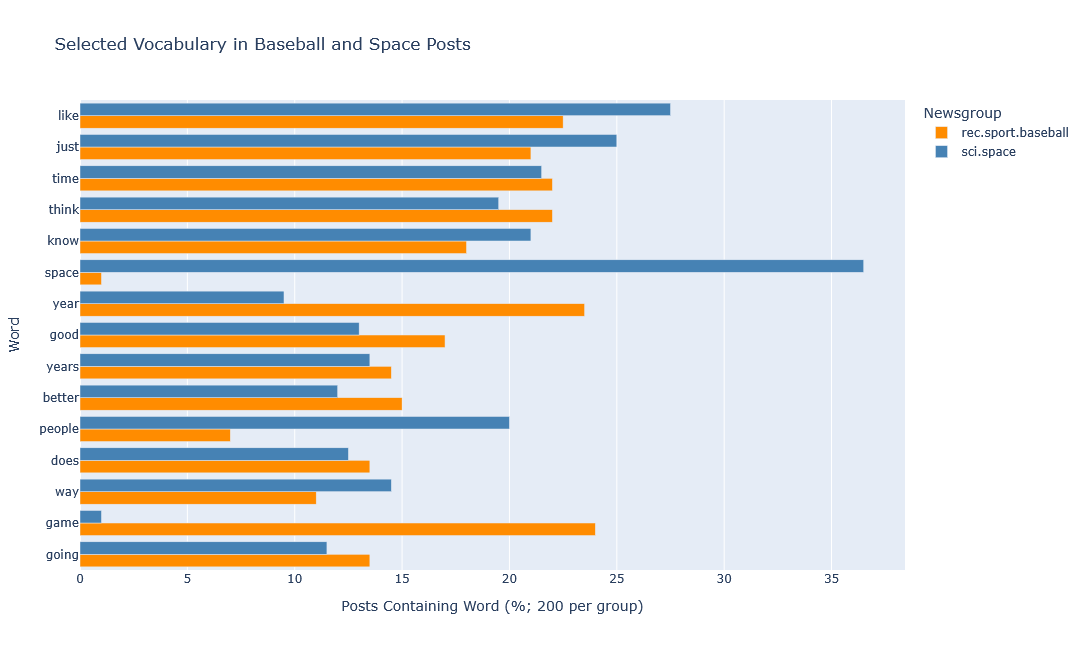

In [28]:
posts_colors = {
    "rec.sport.baseball": "darkorange",
    "sci.space": "steelblue"
}

fig = px.bar(
    posts_plot_df,
    x="percent_documents",
    y="word",
    color="group",
    orientation="h",
    barmode="group",
    category_orders={"word": posts_selected_words},
    color_discrete_map=posts_colors,
    hover_data=["documents_with_word"],
    labels={
        "percent_documents": "Posts Containing Word (%; 200 per group)",
        "word": "Word",
        "group": "Newsgroup"
    },
    title="Selected Vocabulary in Baseball and Space Posts"
)
fig.update_layout(height=650)
fig.show()


**What does Figure 1 show? Describe a pattern and record at least one supporting value, identifying its word or text feature, group, and units.**

Your answer:Figure 1 shows both topic-specific vocabulary and shared conversational words. “Space” appears in approximately 36.5% of space posts compared with 1% of baseball posts. Conversely, “game” appears in approximately 24% of baseball posts versus 1% of space posts. Each percentage uses all 200 sampled posts in its group as the denominator and counts each post once per word.

Words suchixa as “like,” “think,” and “time” occur frequently in both groups, showing shared discussion language alongside topic differences. These are the 15 words with the highest overall document frequencies after the stated stopword removal, not necessarily the 15 most distinctive words.


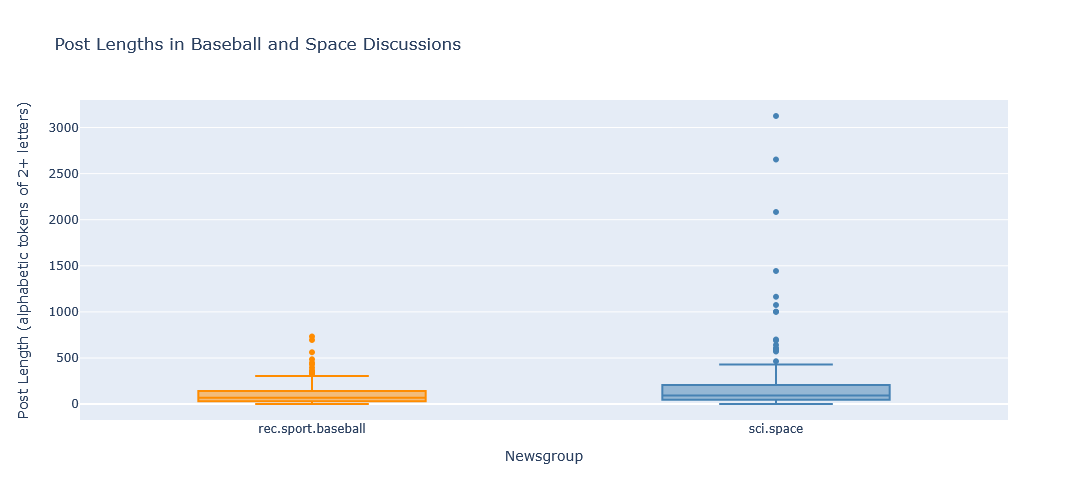

In [29]:
fig = px.box(
    posts_sample_df,
    x="group",
    y="word_count",
    color="group",
    color_discrete_map=posts_colors,
    points="outliers",
    labels={
        "group": "Newsgroup",
        "word_count": "Post Length (alphabetic tokens of 2+ letters)"
    },
    title="Post Lengths in Baseball and Space Discussions"
)
fig.update_layout(height=500, showlegend=False)
fig.show()

**What does Figure 2 add? Record at least one supporting value and compare its message with Figure 1.**

Your answer:Figure 2 shows that sampled space posts generally have greater length and variability than baseball posts. The median is 94 alphabetic tokens for space versus 69 for baseball. The middle 50% spans 46–205 tokens for space and 31–140.75 for baseball. Both distributions have long upper tails; the longest sampled space post contains 3,125 tokens, compared with 732 for baseball.

Figure 1 compares which words occur across posts, while Figure 2 compares document lengths. Longer posts offer more opportunities to contain selected words, so differences in document percentages may partly reflect length as well as topic. Length alone does not measure quality or sentiment.


### Step 4: Check

Verify at least two plotted values against records or calculated summaries. Read a few original texts containing a selected word or illustrating a pattern, using the lecture's sample function or your own code. For grouped comparisons, check examples from each relevant group when matches exist. Explain whether context supports your interpretation. Do not repeat the initial missing-value count.


In [31]:
posts_analyzer = posts_vectorizer.build_analyzer()

for word in ["space", "game"]:
    print("\nWORD:", word)

    for group in ["rec.sport.baseball", "sci.space"]:
        group_df = posts_sample_df.loc[
            posts_sample_df["group"] == group
        ]

        matches = group_df["prepared_text"].apply(
            lambda text: word in posts_analyzer(text)
        )

        print(
            group,
            "Matching posts:", int(matches.sum()),
           "Total:", len(group_df),
            "Percentage:", round(matches.mean() * 100, 1)
        )

        for _, row in group_df.loc[matches].head(2).iterrows():
            print("\nDocument:", row["document_id"])
            print(row["body_text"][:1200])

print("\nPost-length medians:")
display(posts_sample_df.groupby("group")["word_count"].median())



WORD: space
rec.sport.baseball Matching posts: 2 Total: 200 Percentage: 1.0

Document: post_1192

Gant's ML record  Age 28 this season.

Year   G   AB     BA   OBP   SLG   HR   SB  CS
1987   21   83  .265  .271  .386    2    4   2
1988  146  563  .259  .317  .439   19   19  10  <-- 3rd Base Expt. year
1989   75  260  .177  .237  .335    9    9   6
1990  152  575  .303  .357  .539   32   33  16
1991  154  561  .251  .338  .496   32   34  15
1992  153  544  .259  .321  .415   17   32  10

In the majors for parts of 6 seasons, total playing time
approx 4.5 seasons.

Just looking at his hitting record, he's had 2 seasons of OPS
greater than .800, which is pretty good for an OF.  His
1988 season is pretty decent for a rookie 2B.  The move to
third base explains a lot of his 1989.  When he returned as an OF,
he began hitting again.  And of course, last year he slumped.

But no learning curve?  He has obviously improved his batting eye
over the years, as well as his SB/CS ratio.  As to his f

group
rec.sport.baseball    69.0
sci.space             94.0
Name: word_count, dtype: float64

**Which two values did you check, and did they agree? What did the original text reveal that the figures could not? Describe any correction you made.**

Your answer:I checked “space” and “game” using the same tokenization rules as the vocabulary chart. “Space” appeared in 73 of 200 space posts (36.5%) and 2 of 200 baseball posts (1%). “Game” appeared in 48 of 200 baseball posts (24%) and 2 of 200 space posts (1%). These matched the plotted percentages. The post-length medians also matched: 69 tokens for baseball and 94 for space.

The original text revealed different meanings that the figures cannot show. In baseball posts, “space” appeared in phrases such as “the space of a year” and “space correction,” rather than referring to astronomy. In space posts, “game” appeared in expressions such as “fair game” and “Anybody game for a contest?” rather than a baseball game. Thus, a matching word does not always indicate the same topic. No numerical corrections were needed.


### Step 5: Conclusion

Restate your research question, then answer it using evidence from **both** figures. Include numerical values with clear units or denominators and explain whether the evidence supports your prediction.


**Restate your question and write your conclusion.**

Your answer:My question was how vocabulary and post length differ between baseball and space discussions. The vocabulary chart shows topic-related differences: “space” occurs much more often in space posts, while “game” occurs more often in baseball posts. Both groups also share common discussion words.

Among 200 sampled posts per group, the median length was 94 alphabetic tokens for space and 69 for baseball. The box plot shows greater spread and a longer upper tail for space posts. Together, the figures show differences in both vocabulary and document length, although longer posts have more opportunities to contain words.


### Step 6: Limitation

Identify **two limitations of your analysis**. Then explain which aspects of your question are easier or harder to answer from each figure.


**What are two limitations, and how do the strengths and weaknesses of your figures affect the answer?**

Your answer:First, this is a fixed sample of historical Usenet posts, not a representative sample of current baseball or space discussions. Posts may share authors or threads, and removing identical bodies does not make all observations independent.

Second, header and quote removal is imperfect, and tokenization and stopword choices affect vocabulary and length. Document percentages count longer and shorter posts equally even though longer posts offer more opportunities for a word to appear. The bar chart shows selected word prevalence but hides context; the box plot shows length differences but not meaning, quality, or sentiment.


## AI-use reflection


**Did you use AI? If so, describe one suggestion you checked against your source, code, or output and what you accepted, modified, or rejected. If not, state that you did not use it.**

Your answer:I used ChatGPT to help write/explain code, prepare text, and draft interpretations. One suggestion I checked was counting each document only once per word. My output confirmed that “space” appeared in 73 of 200 space posts (36.5%) and 2 of 200 baseball posts (1%), matching the chart. Reading original examples showed that “space” had different meanings across posts. I accepted document percentages for comparison but qualified the interpretation because word presence alone does not establish context. I also added “don” and “ll” to the stopwords after identifying them as contraction fragments.


## Submission checklist

- Include two distinct text datasets and document their sources, feature definitions, collection context, and access dates.
- Review the datasets and displayed language for work appropriateness; document any screening and its effects.
- Ask one research question per dataset and complete all six steps for each question.
- Complete both feature tables and every written response.
- Include four finished figures: two different chart types per question, with at least one numerical comparison per pair.
- Explain text preparation, stopwords, filtering, missing or blank text, duplicates, group sizes, and row counts.
- Define what is counted and the denominator of every percentage.
- Check two plotted values and original text context for each investigation.
- Restate each question in its conclusion and cite evidence from both figures.
- Identify two limitations per investigation and compare what the displays reveal or obscure.
- Include your data files and any preparation code using relative paths. Complete the AI-use reflection, restart the kernel, and run cells in order before submitting.
